In [1]:
import torch
from torch import nn
from torch.nn import functional as F
    
import numpy as np

import pickle

from pathlib import Path
from pprint import pprint

import matplotlib.pyplot as plt

In [2]:
Path.cwd().parent / 'experiment_data'

WindowsPath('d:/College 2/sem 3/LTH/code/lth-efficiency/experiment_data')

In [3]:
experiment_folder = Path.cwd().parent / 'experiment_data'

In [4]:
network_file = experiment_folder / 'subnetworks-e50-r10-p0.2000-t15-s32.pkl'

In [5]:
with open(network_file, 'rb') as f:
    results = pickle.load(f)

In [6]:
pprint(list(results.keys()))

['seeds',
 'config',
 'FC-train-losses',
 'FC-train-accs',
 'FC-test-losses',
 'FC-test-accs',
 'sparsity-per-round',
 'winning-tickets',
 'winning-tickets-full-initializations',
 'winning-ticket-masks',
 'pruned-train-loss-before',
 'pruned-train-acc-before',
 'pruned-test-loss-before',
 'pruned-test-acc-before',
 'pruned-train-loss-after',
 'pruned-train-acc-after',
 'pruned-test-loss-after',
 'pruned-test-acc-after',
 'trained-tickets']


In [7]:
results.keys()

dict_keys(['seeds', 'config', 'FC-train-losses', 'FC-train-accs', 'FC-test-losses', 'FC-test-accs', 'sparsity-per-round', 'winning-tickets', 'winning-tickets-full-initializations', 'winning-ticket-masks', 'pruned-train-loss-before', 'pruned-train-acc-before', 'pruned-test-loss-before', 'pruned-test-acc-before', 'pruned-train-loss-after', 'pruned-train-acc-after', 'pruned-test-loss-after', 'pruned-test-acc-after', 'trained-tickets'])

In [8]:
net1 = results['winning-tickets'][0]
net2 = results['winning-tickets'][1]

In [9]:
mask1 = results['winning-ticket-masks'][0]
mask2 = results['winning-ticket-masks'][1]

In [10]:
results['winning-tickets'][10]['1.weight'].shape

torch.Size([32, 784])

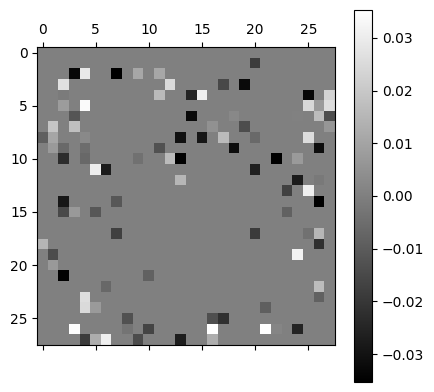

In [20]:
cax = plt.matshow(results['winning-tickets'][10]['1.weight'].reshape((32, 28, 28))[17], cmap='grey')
plt.colorbar(cax)

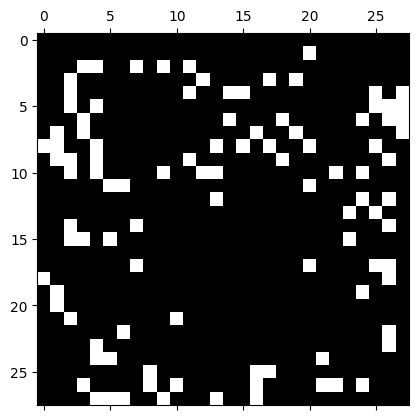

In [12]:
plt.matshow(results['winning-ticket-masks'][10]['1.weight'].reshape((32, 28, 28))[17], cmap='grey')

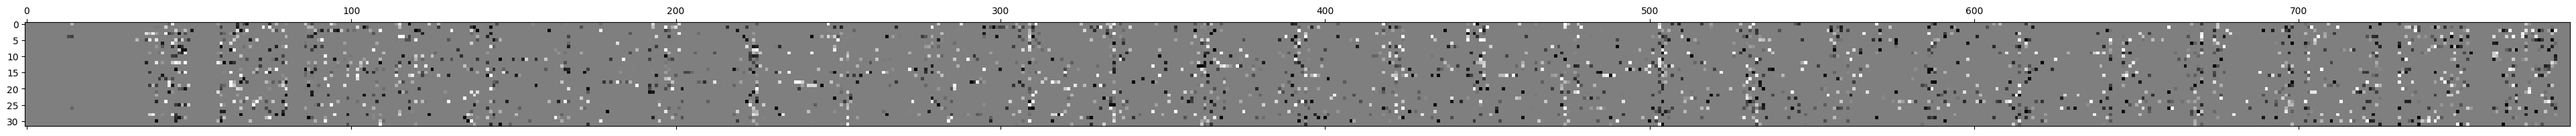

In [13]:
plt.matshow(net2['1.weight'], cmap='grey')
plt.gcf().set_figwidth(100)

In [14]:
def compare_first_layer(net1: nn.Module, net2: nn.Module):
    assert net1.keys() == net2.keys()

    weight_vec_1 = torch.concat([net1['1.weight'], net1['1.bias'].unsqueeze(dim=1)], dim=1)
    weight_vec_2 = torch.concat([net2['1.weight'], net2['1.bias'].unsqueeze(dim=1)], dim=1)

    similarity_mat = torch.matmul(F.normalize(weight_vec_1, p=2, dim=1), F.normalize(weight_vec_2, p=2, dim=1))
    print(similarity_mat)

# compare_first_layer(net1, net2)

In [15]:
from scipy.optimize import linear_sum_assignment

def compare_first_layer(net1: nn.Module, net2: nn.Module):
    assert net1.keys() == net2.keys()

    weight_vec_1 = torch.concat([net1['1.weight'], net1['1.bias'].unsqueeze(dim=1)], dim=1)
    weight_vec_2 = torch.concat([net2['1.weight'], net2['1.bias'].unsqueeze(dim=1)], dim=1)

    similarity_mat = torch.matmul(F.normalize(weight_vec_1, p=2, dim=1), F.normalize(weight_vec_2, p=2, dim=1).T)

    # assert torch.allclose(similarity_mat.diag(), F.cosine_similarity(weight_vec_1, weight_vec_2))

    cost_mat = -similarity_mat
    row_ind, col_ind = linear_sum_assignment(cost_mat)
    
    best_costs = similarity_mat[row_ind, col_ind]
    mean_sim = torch.mean(best_costs)

    return mean_sim
    

compare_first_layer(net1, net2)

tensor(0.0775)

In [16]:
test_mat = torch.rand(size=(3, 5))

In [17]:
(test_mat[torch.arange(test_mat.shape[0]), :] == test_mat).all()

tensor(True)

In [18]:
test_mat

tensor([[0.7130, 0.6462, 0.0555, 0.8489, 0.7628],
        [0.5015, 0.3523, 0.6480, 0.7510, 0.3916],
        [0.7369, 0.3666, 0.3481, 0.2212, 0.5195]])

In [21]:
test_mat[torch.randperm(test_mat.shape[0]), :]

tensor([[0.7130, 0.6462, 0.0555, 0.8489, 0.7628],
        [0.7369, 0.3666, 0.3481, 0.2212, 0.5195],
        [0.5015, 0.3523, 0.6480, 0.7510, 0.3916]])

In [22]:
A = torch.tensor([[1,2,3],[4,5,6],[7,8,9]])
B = torch.tensor([[9,8,7],[6,5,4],[3,2,1]])

print(A)
print(B)
print(torch.matmul(A, B.T))

tensor([[1, 2, 3],
        [4, 5, 6],
        [7, 8, 9]])
tensor([[9, 8, 7],
        [6, 5, 4],
        [3, 2, 1]])
tensor([[ 46,  28,  10],
        [118,  73,  28],
        [190, 118,  46]])


In [23]:
def mean_cossim_layer(net1: nn.Module, net2: nn.Module, layer, alignment = None):
    '''
    `alignment` should be a list, ndarray or tensor that contains an alignment from net1 to net2
    i.e. if index i contains value j, then input i in net1[layer] is mapped to input j in net2[layer].
    Both net1[layer] and net2[layer] MUST be torch.nn.Linear ONLY.
    '''

    

    # weight_vec_1 = torch.rand(size=(3, 5))
    # weight_vec_2 = torch.rand(size=(3, 5))
    
    weight_vec_1 = net1[f'{layer}.weight']
    weight_vec_2 = net2[f'{layer}.weight']

    if alignment is None:
        alignment = torch.arange(weight_vec_1.shape[1])
    
    assert (np.array(alignment).shape[0] == weight_vec_1.shape[1]), f'{weight_vec_1.shape=}, {alignment.shape=}'

    weight_vec_2 = weight_vec_2[:, alignment]

    weight_vec_1 = torch.concat([net1[f'{layer}.weight'], net1[f'{layer}.bias'].unsqueeze(dim=1)], dim=1)
    weight_vec_2 = torch.concat([weight_vec_2, net2[f'{layer}.bias'].unsqueeze(dim=1)], dim=1)
    
    similarity_mat = torch.matmul(F.normalize(weight_vec_1, p=2, dim=1), F.normalize(weight_vec_2, p=2, dim=1).T)

    assert torch.allclose(similarity_mat.diag(), F.cosine_similarity(weight_vec_1, weight_vec_2))

    cost_mat = -similarity_mat
    row_ind, col_ind = linear_sum_assignment(cost_mat)
    
    best_sims = similarity_mat[row_ind, col_ind]
    mean_sim = torch.mean(best_sims)

    return mean_sim, col_ind

def mean_cossim_layer_fixed_identities(net1, net2, layer, alignment = None):
    '''
    Basically the same as `mean_cossim_layer` but assumes that the current neurons are one-to-one, so skips the linear sum assignment.
    Note however it does NOT assume the same about the previous layer so it still requires an alignment vector. Still returns a `None` in place of a forward alignment 
    to be consistent.
    '''

    weight_vec_1 = net1[f'{layer}.weight']
    weight_vec_2 = net2[f'{layer}.weight']

    if alignment is None:
        alignment = torch.arange(weight_vec_1.shape[1])
    
    assert (np.array(alignment).shape[0] == weight_vec_1.shape[1]), f'{weight_vec_1.shape=}, {alignment.shape=}'

    weight_vec_2 = weight_vec_2[:, alignment]

    weight_vec_1 = torch.concat([net1[f'{layer}.weight'], net1[f'{layer}.bias'].unsqueeze(dim=1)], dim=1)
    weight_vec_2 = torch.concat([weight_vec_2, net2[f'{layer}.bias'].unsqueeze(dim=1)], dim=1)
    
    # similarity_mat = torch.matmul(F.normalize(weight_vec_1, p=2, dim=1), F.normalize(weight_vec_2, p=2, dim=1).T)
    best_sims = F.cosine_similarity(weight_vec_1, weight_vec_2)
    mean_sim = torch.mean(best_sims)

    return mean_sim, None


mean_cossim_layer_fixed_identities(net1, net2, 3, alignment=None)
    

C:\Users\Sukrit\AppData\Local\Temp\ipykernel_31192\1776579943.py:51: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  assert (np.array(alignment).shape[0] == weight_vec_1.shape[1]), f'{weight_vec_1.shape=}, {alignment.shape=}'


(tensor(0.0521), None)

In [24]:
def compute_net_similarity(net1, net2):
    layers = list(net1.keys())
    layers = map(lambda x: x.split('.')[0], layers)
    layers = list(set(layers))
    layers.sort()
    alignment = None
    
    means = []
    for i, layer in enumerate(layers):
        if i == len(layers) - 1: break
        
        layer_sim_mean, alignment = mean_cossim_layer(net1, net2, layer, alignment=alignment)
        means.append(layer_sim_mean)

    layer_sim_mean, _ = mean_cossim_layer_fixed_identities(net1, net2, layers[-1], alignment=alignment)
    means.append(layer_sim_mean)
    return np.mean(means)

compute_net_similarity(net1, net2)

C:\Users\Sukrit\AppData\Local\Temp\ipykernel_31192\1776579943.py:19: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  assert (np.array(alignment).shape[0] == weight_vec_1.shape[1]), f'{weight_vec_1.shape=}, {alignment.shape=}'


np.float32(0.03551619)

In [50]:
sims = []

for _ in range(1000000):
    v1, v2 = np.random.uniform(-1, 1, size=784), np.random.uniform(-1, 1, size=784)
    cos_sim = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))
    sims.append(cos_sim)

print(np.var(sims), 1/784)

0.001273846383806956 0.0012755102040816326


In [51]:
similarities = []

key = 'winning-tickets'
print(f'Measuring {key}')
for i, net1 in enumerate(results[key]):
    for j, net2 in enumerate(results[key]):
        if i == j: continue
         
        # similarities.append(mean_cossim_layer(net1, net2, layer='1')[0])
        # similarities.append(compare_first_layer(net1, net2))
        similarities.append(compare_first_layer(net1, net2))

mean_net_sim = np.mean(similarities)
std_net_sim = np.std(similarities)
print(mean_net_sim)
print(std_net_sim)

Measuring winning-tickets
0.08261321
0.0048105614


In [52]:
pprint(similarities)

[tensor(0.0775),
 tensor(0.0811),
 tensor(0.0839),
 tensor(0.0798),
 tensor(0.0816),
 tensor(0.0839),
 tensor(0.0812),
 tensor(0.0787),
 tensor(0.0791),
 tensor(0.0833),
 tensor(0.0828),
 tensor(0.0884),
 tensor(0.0747),
 tensor(0.0785),
 tensor(0.0775),
 tensor(0.0823),
 tensor(0.0871),
 tensor(0.0909),
 tensor(0.0851),
 tensor(0.0872),
 tensor(0.0791),
 tensor(0.0900),
 tensor(0.0849),
 tensor(0.0894),
 tensor(0.0842),
 tensor(0.0918),
 tensor(0.0782),
 tensor(0.0867),
 tensor(0.0811),
 tensor(0.0823),
 tensor(0.0826),
 tensor(0.0887),
 tensor(0.0826),
 tensor(0.0793),
 tensor(0.0828),
 tensor(0.0871),
 tensor(0.0808),
 tensor(0.0866),
 tensor(0.0880),
 tensor(0.0762),
 tensor(0.0818),
 tensor(0.0780),
 tensor(0.0839),
 tensor(0.0871),
 tensor(0.0826),
 tensor(0.0817),
 tensor(0.0832),
 tensor(0.0832),
 tensor(0.0804),
 tensor(0.0777),
 tensor(0.0780),
 tensor(0.0891),
 tensor(0.0842),
 tensor(0.0801),
 tensor(0.0732),
 tensor(0.0790),
 tensor(0.0798),
 tensor(0.0909),
 tensor(0.0887

In [53]:


values = []
for _ in range(1000):
    similarity_mat = np.random.normal(0, 1/np.sqrt(784), size=(32, 32)) #TODO: is 1/sqrt(n) the correct stddev? validate.
    cost_mat = -similarity_mat
    row_ind, col_ind = linear_sum_assignment(cost_mat)

    best_costs = similarity_mat[row_ind, col_ind]
    mean_sim = np.mean(best_costs)
    values.append(mean_sim)

print(np.mean(values))
print(np.std(values))
print(f'95% conf int: {np.mean(values) - 1.645*np.std(values)} -- {np.mean(values) + 1.645*np.std(values)}')

0.06713758569841048
0.0029052013694401825
95% conf int: 0.062358529445681384 -- 0.07191664195113959


In [54]:
print(f'MEAN SIMILARITY = {mean_net_sim}')

MEAN SIMILARITY = 0.08261320739984512


In [55]:
print(f'{(mean_net_sim - 0.06713758569841048) / 0.0029052013694401825:.1f}σ result')

5.3σ result


# Alignment-wise neuron calculation

In [31]:
alignments = {}

for i, net1 in enumerate(results['winning-tickets']):
    for j, net2 in enumerate(results['winning-tickets']):

        sim, align = mean_cossim_layer(net1, net2, layer=1)

        alignments[(i, j)] = align

C:\Users\Sukrit\AppData\Local\Temp\ipykernel_31192\1776579943.py:19: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  assert (np.array(alignment).shape[0] == weight_vec_1.shape[1]), f'{weight_vec_1.shape=}, {alignment.shape=}'


In [56]:
def display_comparison(netidx1, netidx2, unitidx, alignments_dict):
    alignment = alignments_dict[(netidx1, netidx2)]

    net1, net2 = results['winning-tickets'][netidx1], results['winning-tickets'][netidx2]
    mat1 = net1['1.weight']
    mat2 = net2['1.weight'][alignment]


    vec1 = mat1[unitidx]
    vec2 = mat2[unitidx]

    fig, ax = plt.subplots(1, 2)
    ax[0].matshow(vec1.reshape((28, 28)), cmap='gray')
    ax[1].matshow(vec2.reshape((28, 28)), cmap='gray')

    ax[0].set_title(f'network {netidx1}, unit {unitidx}')
    ax[1].set_title(f'network {netidx2}, unit {alignment[unitidx]}')


def display_across_all(anchor_network, unitidx, alignments_dict, trained=False):

    fig, ax = plt.subplots(3, 5, figsize=(8*2, 5*2))
    ax = ax.flatten()
    for i in range(len(results['winning-tickets'])):
        alignment = alignments_dict[(anchor_network, i)]

        if not trained:
            net1, net2 = results['winning-tickets'][anchor_network], results['winning-tickets'][i]
        else:
            net1, net2 = results['trained-tickets'][anchor_network], results['trained-tickets'][i]
        mat1 = net1['1.weight']
        mat2 = net2['1.weight'][alignment]

        vec1 = mat1[unitidx]
        vec2 = mat2[unitidx]

        ax[i].matshow(vec2.reshape((28, 28)))
        ax[i].set_xticks([])
        ax[i].set_yticks([])
        ax[i].set_title(f'n={i}, u={alignment[unitidx]}', fontsize=10)


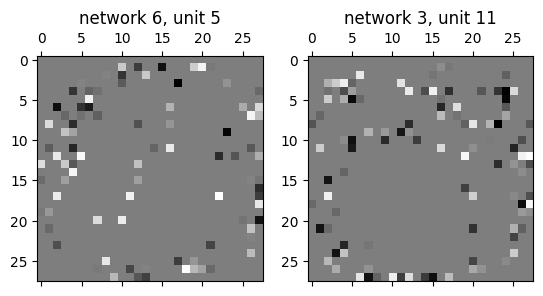

In [57]:
display_comparison(6, 3, 5, alignments)

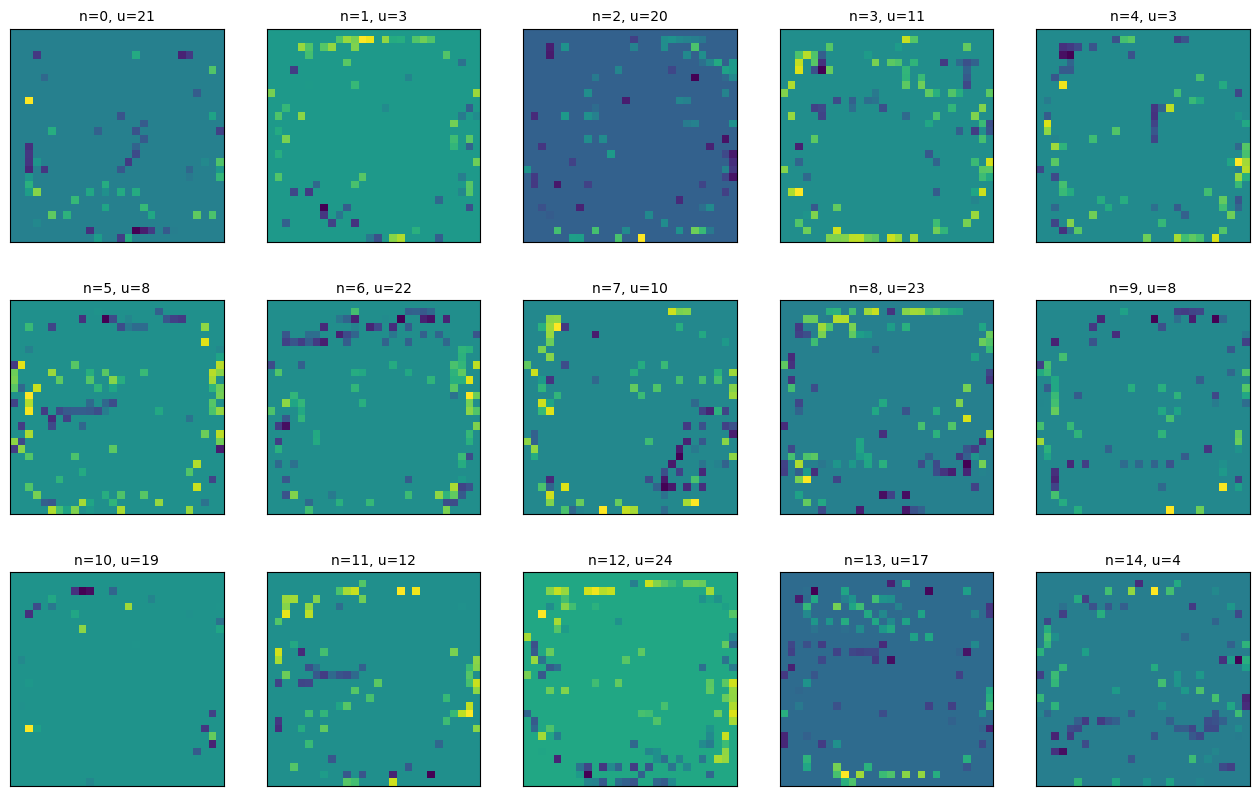

In [59]:
display_across_all(anchor_network=7, unitidx=10, alignments_dict=alignments, trained=True)

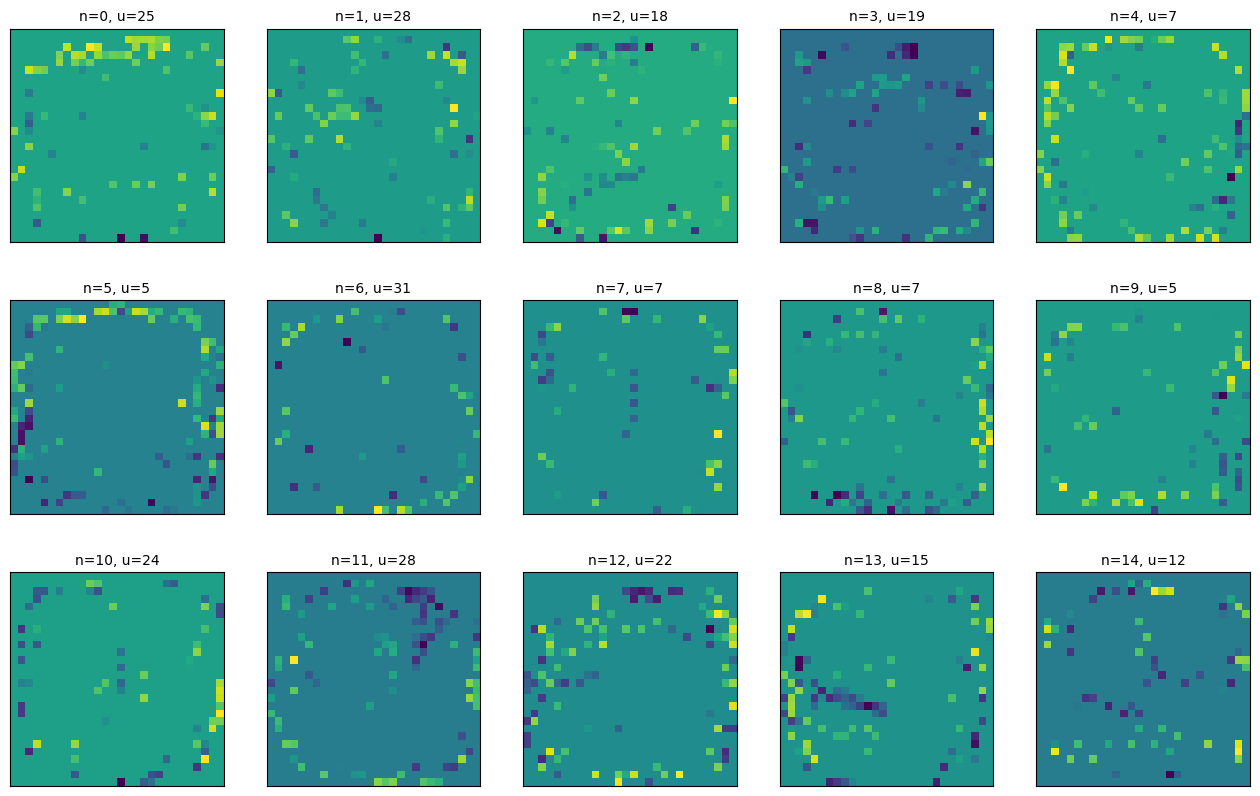

In [60]:
display_across_all(anchor_network=7, unitidx=7, alignments_dict=alignments, trained=True)

### Followup needed: Do the same thing with the jaccard of the masks

In [10]:
def jaccard(x1: torch.Tensor, x2: torch.Tensor):
    '''
    Compute the jaccard similarity between the two given binary tensors. Assumes both tensors are binary, i.e. have only zero and one as values.
    '''

    intersection = torch.logical_and(x1, x2)
    union = torch.logical_or(x1, x2)

    return intersection.sum() / union.sum()


In [ ]:
from typing import Literal

def compare_first_layer_mask(mask1: dict, mask2: dict, dead_default: Literal['zero', 'one'] = 'zero'):
    assert mask1.keys() == mask2.keys()

    m1 = torch.concat([mask1['1.weight'], mask1['1.bias'].unsqueeze(dim=1)], dim=1).float()
    m2 = torch.concat([mask2['1.weight'], mask2['1.bias'].unsqueeze(dim=1)], dim=1).float()

    intersection = m1 @ m2.T
    union = m1.sum(dim=1, keepdim=True) + m2.sum(dim=1) - intersection

    if dead_default == 'zero':
        similarity_mat = torch.where(union > 0, intersection / union.clamp(min=1), torch.zeros_like(union))
    elif dead_default == 'one':
        similarity_mat = torch.where(union > 0, intersection / union.clamp(min=1), torch.ones_like(union))
    else: 
        raise TypeError("'dead_default' must be one of 'zero' or 'one'")

    row_ind, col_ind = linear_sum_assignment(-similarity_mat.numpy())
    return similarity_mat[row_ind, col_ind].mean()

compare_first_layer_mask(mask1, mask2)

tensor(0.1637)